In [34]:
import tensorflow as tf
from tensorflow import keras

In [35]:
vocab_size = 5000

In [36]:
import numpy as np
import pandas as pd


In [37]:
df = pd.read_csv('/content/spam.csv', encoding='latin-1')

In [38]:
df

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN
...,...,...,...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...,NaN,NaN,NaN
5568,ham,Will Ì_ b going to esplanade fr home?,NaN,NaN,NaN
5569,ham,"Pity, * was in mood for that. So...any other s...",NaN,NaN,NaN
5570,ham,The guy did some bitching but I acted like i'd...,NaN,NaN,NaN


In [39]:
# 1. Initial Data Inspection

print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nDescriptive Statistics:")
display(df.describe(include='all'))

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nClass Distribution:")
print(df['v1'].value_counts())

print("\nClass Distribution (%):")
print(df['v1'].value_counts(normalize=True) * 100)

Dataset Shape: (5572, 5)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB

Descriptive Statistics:


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
count,5572,5572,50,12,6
unique,2,5169,43,10,5
top,ham,"Sorry, I'll call later","bt not his girlfrnd... G o o d n i g h t . . .@""","MK17 92H. 450Ppw 16""","GNT:-)"""
freq,4825,30,3,2,2



Missing Values:
v1               0
v2               0
Unnamed: 2    5522
Unnamed: 3    5560
Unnamed: 4    5566
dtype: int64

Duplicate Rows: 403

Class Distribution:
v1
ham     4825
spam     747
Name: count, dtype: int64

Class Distribution (%):
v1
ham     86.593683
spam    13.406317
Name: proportion, dtype: float64


### Initial Data Inspection — Observations

- The dataset contains SMS messages and their corresponding labels, which identify messages as ham or spam.
- The class distribution was examined to determine whether ham and spam messages were imbalanced. This is important because class imbalance can affect a classifier's performance, particularly its ability to identify spam.
- Missing values, column data types, and duplicate records were inspected to identify data-quality issues before performing exploratory data analysis and feature engineering.

In [40]:
# Remove empty or unnecessary columns created during CSV import
unnamed_cols = df.columns[df.columns.str.contains(r'^Unnamed', case=False)]

print("Unnamed columns:", list(unnamed_cols))
print("\nMissing values in these columns:")
print(df[unnamed_cols].isnull().sum())

# Drop Unnamed columns because they are not part of the SMS message data
df.drop(columns=unnamed_cols, inplace=True)

print("\nDataset shape after dropping Unnamed columns:", df.shape)
print("Remaining columns:", df.columns.tolist())

Unnamed columns: ['Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']

Missing values in these columns:
Unnamed: 2    5522
Unnamed: 3    5560
Unnamed: 4    5566
dtype: int64

Dataset shape after dropping Unnamed columns: (5572, 2)
Remaining columns: ['v1', 'v2']


**Data Cleaning Observation:** The dataset contained additional `Unnamed` columns that were mostly empty and did not represent meaningful SMS features. These columns were removed to prevent unnecessary data from affecting subsequent analysis. The remaining columns contain the message labels and SMS text required for the classification task.

In [41]:
# 2. Data Cleaning

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Remove rows with missing labels or messages
df = df.dropna(subset=['v1', 'v2']).copy()

# Normalize labels
df['v1'] = df['v1'].str.strip().str.lower()

# Keep only valid labels
df = df[df['v1'].isin(['ham', 'spam'])].copy()

# Convert messages to strings
df['v2'] = df['v2'].astype(str)

print("Shape after cleaning:", df.shape)
print("Missing values:\n", df.isnull().sum())
print("Remaining duplicates:", df.duplicated().sum())
print("Labels:\n", df['v1'].value_counts())

Shape after cleaning: (5169, 2)
Missing values:
 v1    0
v2    0
dtype: int64
Remaining duplicates: 0
Labels:
 v1
ham     4516
spam     653
Name: count, dtype: int64


In [42]:
import matplotlib.pyplot as plt
import seaborn as sns

df['message_length'] = df['v2'].str.len()

df['word_count'] = df['v2'].str.split().str.len()

print(df[['v1', 'v2', 'message_length', 'word_count']].head())

print("\nMessage Length Statistics:")
print(df['message_length'].describe())

     v1                                                 v2  message_length  \
0   ham  Go until jurong point, crazy.. Available only ...             111   
1   ham                      Ok lar... Joking wif u oni...              29   
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...             155   
3   ham  U dun say so early hor... U c already then say...              49   
4   ham  Nah I don't think he goes to usf, he lives aro...              61   

   word_count  
0          20  
1           6  
2          28  
3          11  
4          13  

Message Length Statistics:
count    5169.000000
mean       78.977945
std        58.236293
min         2.000000
25%        36.000000
50%        60.000000
75%       117.000000
max       910.000000
Name: message_length, dtype: float64


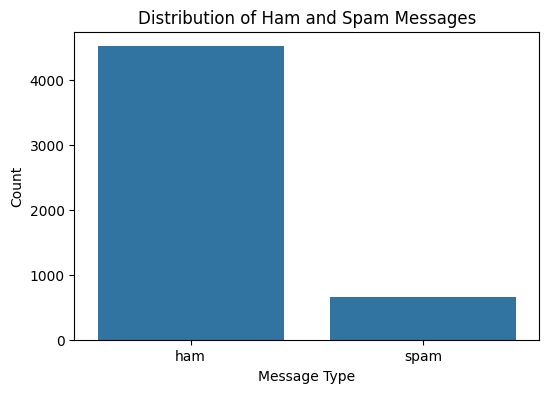

In [43]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='v1')
plt.title('Distribution of Ham and Spam Messages')
plt.xlabel('Message Type')
plt.ylabel('Count')
plt.show()

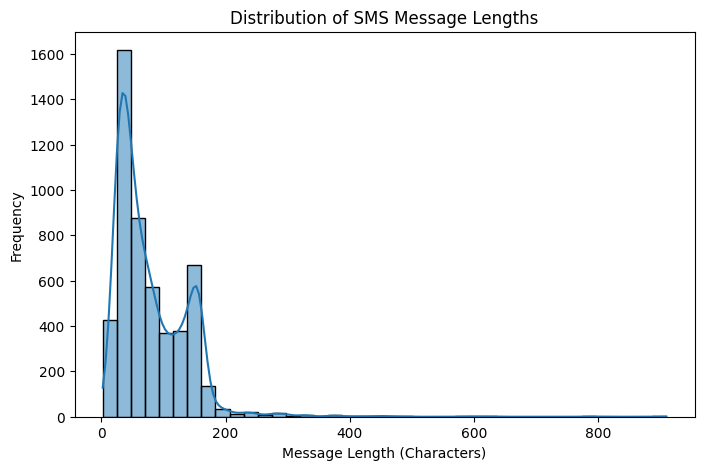

In [44]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='message_length', bins=40, kde=True)
plt.title('Distribution of SMS Message Lengths')
plt.xlabel('Message Length (Characters)')
plt.ylabel('Frequency')
plt.show()

In [45]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import string

# Create numerical features for EDA and potential model use
df['message_length'] = df['v2'].str.len()
df['word_count'] = df['v2'].str.split().str.len()

def uppercase_ratio(text):
    letters = [char for char in text if char.isalpha()]
    return sum(char.isupper() for char in letters) / len(letters) if letters else 0

df['uppercase_ratio'] = df['v2'].apply(uppercase_ratio)

df['punctuation_count'] = df['v2'].apply(
    lambda text: sum(char in string.punctuation for char in text)
)

df['has_url'] = df['v2'].str.contains(
    r'https?://|www\.',
    case=False,
    regex=True
).astype(int)

df['has_phone_number'] = df['v2'].str.contains(
    r'\b(?:\+?\d[\d\s().-]{6,}\d)\b',
    regex=True
).astype(int)

df['label'] = df['v1'].map({'ham': 0, 'spam': 1})

display(df.head())

,v1,v2,message_length,word_count,uppercase_ratio,punctuation_count,has_url,has_phone_number,label
0,ham,"Go until jurong point, crazy.. Available only ...",111,20,0.036145,9,0,0,0
1,ham,Ok lar... Joking wif u oni...,29,6,0.111111,6,0,0,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155,28,0.103093,6,0,0,1
3,ham,U dun say so early hor... U c already then say...,49,11,0.060606,6,0,0,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",61,13,0.042553,2,0,0,0


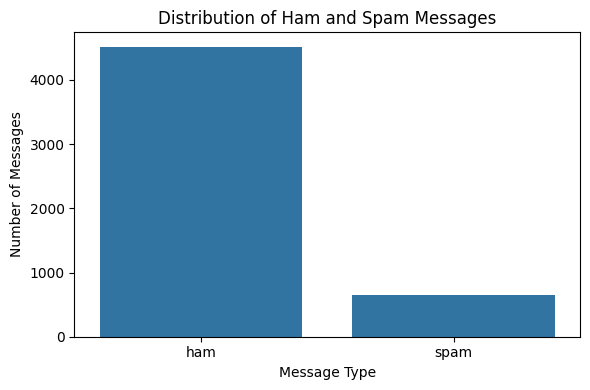

In [46]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='v1')
plt.title('Distribution of Ham and Spam Messages')
plt.xlabel('Message Type')
plt.ylabel('Number of Messages')
plt.tight_layout()
plt.show()

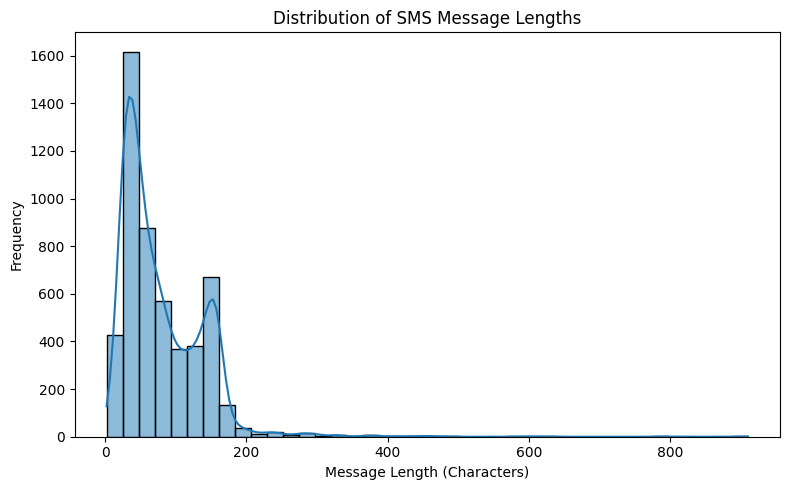

In [47]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='message_length', bins=40, kde=True)
plt.title('Distribution of SMS Message Lengths')
plt.xlabel('Message Length (Characters)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

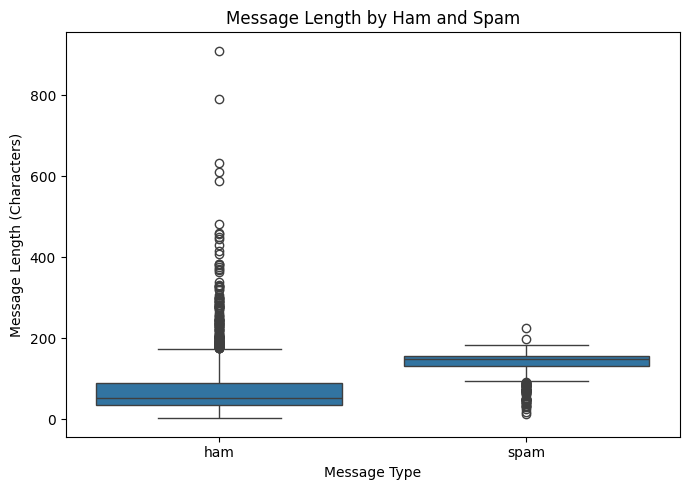

In [48]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x='v1', y='message_length')
plt.title('Message Length by Ham and Spam')
plt.xlabel('Message Type')
plt.ylabel('Message Length (Characters)')
plt.tight_layout()
plt.show()

In [49]:
Q1 = df['message_length'].quantile(0.25)
Q3 = df['message_length'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = max(0, Q1 - 1.5 * IQR)
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df['message_length'] < lower_bound) |
    (df['message_length'] > upper_bound)
]

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of Potential Outliers:", len(outliers))

display(
    outliers[['v1', 'v2', 'message_length']]
    .sort_values('message_length', ascending=False)
    .head(10)
)

Lower Bound: 0
Upper Bound: 238.5
Number of Potential Outliers: 66


,v1,v2,message_length
1084,ham,For me the love should start with attraction.i...,910
1862,ham,The last thing i ever wanted to do was hurt yo...,790
2433,ham,Indians r poor but India is not a poor country...,632
1578,ham,How to Make a girl Happy? It's not at all diff...,611
2157,ham,Sad story of a Man - Last week was my b'day. M...,588
2379,ham,"Good evening Sir, hope you are having a nice d...",482
3015,ham,"&lt;#&gt; is fast approaching. So, Wish u a v...",461
1512,ham,"Hey sweet, I was wondering when you had a mome...",458
2369,ham,A Boy loved a gal. He propsd bt she didnt mind...,450
2407,ham,Solve d Case : A Man Was Found Murdered On &l...,444


### Outlier Analysis — Conclusion

The IQR method identified 66 potential outliers based on message length. These observations were treated as potential outliers rather than automatic data errors because unusually long SMS messages may contain legitimate promotional content, URLs, or other information relevant to spam detection. Therefore, the messages were retained to preserve potentially useful information for classification.

In [50]:
import string

# 5. Feature Engineering

# Character count
df['message_length'] = df['v2'].str.len()

# Word count
df['word_count'] = df['v2'].str.split().str.len()

# Ratio of uppercase characters
def uppercase_ratio(text):
    letters = [char for char in text if char.isalpha()]
    if len(letters) == 0:
        return 0
    return sum(char.isupper() for char in letters) / len(letters)

df['uppercase_ratio'] = df['v2'].apply(uppercase_ratio)

# Count punctuation characters
df['punctuation_count'] = df['v2'].apply(
    lambda text: sum(char in string.punctuation for char in text)
)

# URL indicator
df['has_url'] = df['v2'].str.contains(
    r'https?://|www\.',
    case=False,
    regex=True
).astype(int)

# Phone-number indicator
df['has_phone_number'] = df['v2'].str.contains(
    r'\b(?:\+?\d[\d\s().-]{6,}\d)\b',
    regex=True
).astype(int)

# Encode target label
df['label'] = df['v1'].map({'ham': 0, 'spam': 1})

display(
    df[
        [
            'v1',
            'v2',
            'message_length',
            'word_count',
            'uppercase_ratio',
            'punctuation_count',
            'has_url',
            'has_phone_number',
            'label'
        ]
    ].head(10)
)

,v1,v2,message_length,word_count,uppercase_ratio,punctuation_count,has_url,has_phone_number,label
0,ham,"Go until jurong point, crazy.. Available only ...",111,20,0.036145,9,0,0,0
1,ham,Ok lar... Joking wif u oni...,29,6,0.111111,6,0,0,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155,28,0.103093,6,0,0,1
3,ham,U dun say so early hor... U c already then say...,49,11,0.060606,6,0,0,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",61,13,0.042553,2,0,0,0
5,spam,FreeMsg Hey there darling it's been 3 week's n...,148,32,0.067308,8,0,0,1
6,ham,Even my brother is not like to speak with me. ...,77,16,0.033333,2,0,0,0
7,ham,As per your request 'Melle Melle (Oru Minnamin...,160,26,0.078125,6,0,0,0
8,spam,WINNER!! As a valued network customer you have...,158,26,0.112150,6,0,1,1
9,spam,Had your mobile 11 months or more? U R entitle...,154,29,0.126126,2,0,1,1


In [51]:
print("Average message length by label:")
print(df.groupby('v1')['message_length'].mean())

print("\nAverage word count by label:")
print(df.groupby('v1')['word_count'].mean())

print("\nURL frequency by label:")
print(pd.crosstab(df['v1'], df['has_url'], normalize='index'))

print("\nPhone-number frequency by label:")
print(pd.crosstab(df['v1'], df['has_phone_number'], normalize='index'))

Average message length by label:
v1
ham      70.459256
spam    137.891271
Name: message_length, dtype: float64

Average word count by label:
v1
ham     14.134632
spam    23.681470
Name: word_count, dtype: float64

URL frequency by label:
has_url         0         1
v1                         
ham      0.999779  0.000221
spam     0.862175  0.137825

Phone-number frequency by label:
has_phone_number         0         1
v1                                  
ham               0.998893  0.001107
spam              0.451761  0.548239


In [52]:
# Dataset and class statistics
print("Final dataset shape:", df.shape)

print("\nClass counts:")
print(df['v1'].value_counts())

print("\nClass percentages:")
print((df['v1'].value_counts(normalize=True) * 100).round(2))

print("\nAverage message length by label:")
print(df.groupby('v1')['message_length'].mean().round(2))

print("\nMedian message length by label:")
print(df.groupby('v1')['message_length'].median())

print("\nAverage word count by label:")
print(df.groupby('v1')['word_count'].mean().round(2))

print("\nURL frequency by label (%):")
print(
    (pd.crosstab(df['v1'], df['has_url'], normalize='index') * 100).round(2)
)

print("\nPhone-number frequency by label (%):")
print(
    (pd.crosstab(df['v1'], df['has_phone_number'], normalize='index') * 100).round(2)
)

print("\nUppercase ratio by label:")
print(df.groupby('v1')['uppercase_ratio'].mean().round(4))

print("\nPunctuation count by label:")
print(df.groupby('v1')['punctuation_count'].mean().round(2))

Final dataset shape: (5169, 9)

Class counts:
v1
ham     4516
spam     653
Name: count, dtype: int64

Class percentages:
v1
ham     87.37
spam    12.63
Name: proportion, dtype: float64

Average message length by label:
v1
ham      70.46
spam    137.89
Name: message_length, dtype: float64

Median message length by label:
v1
ham      52.0
spam    149.0
Name: message_length, dtype: float64

Average word count by label:
v1
ham     14.13
spam    23.68
Name: word_count, dtype: float64

URL frequency by label (%):
has_url      0      1
v1                   
ham      99.98   0.02
spam     86.22  13.78

Phone-number frequency by label (%):
has_phone_number      0      1
v1                            
ham               99.89   0.11
spam              45.18  54.82

Uppercase ratio by label:
v1
ham     0.0783
spam    0.1651
Name: uppercase_ratio, dtype: float64

Punctuation count by label:
v1
ham     3.87
spam    5.65
Name: punctuation_count, dtype: float64


In [53]:
X = df['v2'].astype(str).values
y = df['label'].values

In [54]:
from sklearn.model_selection import train_test_split

In [55]:
X_train , X_test , y_train , y_test = train_test_split(X,y,train_size=0.8,random_state=42)

In [56]:
fix_len = 250

In [57]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [58]:
tokenizer = Tokenizer(num_words=5000, oov_token='<OOV>')
tokenizer.fit_on_texts(X_train)

X_train_token = tokenizer.texts_to_sequences(X_train)
X_test_token = tokenizer.texts_to_sequences(X_test)


In [59]:
from keras.preprocessing.sequence import pad_sequences

X_train_pad  = pad_sequences(X_train_token,maxlen=fix_len,padding='post',truncating='post')
X_test_pad = pad_sequences(X_test_token,maxlen=fix_len,padding='post',truncating='post')

In [60]:
y_train

array([0, 0, 0, ..., 0, 0, 1])

In [61]:
np.unique(y_train)

array([0, 1])

In [62]:
from keras.layers import Input , Embedding , SimpleRNN , Dense
from keras.models import Sequential

model = Sequential([
    Input(shape=(fix_len,)),
    Embedding(input_dim=vocab_size,output_dim=16),
    SimpleRNN(64,activation='tanh'),
    Dense(1,activation='sigmoid')
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 250, 16)        │        80,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 64)             │         5,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 85,249 (333.00 KB)

 Trainable params: 85,249 (333.00 KB)

 Non-trainable params: 0 (0.00 B)

In [63]:
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

In [64]:
history = model.fit(X_train_pad,y_train,epochs=5,validation_split=0.2,batch_size=128)

Epoch 1/5
26/26 ━━━━━━━━━━━━━━━━━━━━ 4s 98ms/step - accuracy: 0.8733 - loss: 0.3987 - val_accuracy: 0.8924 - val_loss: 0.3529
Epoch 2/5
26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 88ms/step - accuracy: 0.8733 - loss: 0.3819 - val_accuracy: 0.8924 - val_loss: 0.3418
Epoch 3/5
26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 88ms/step - accuracy: 0.8733 - loss: 0.3806 - val_accuracy: 0.8924 - val_loss: 0.3417
Epoch 4/5
26/26 ━━━━━━━━━━━━━━━━━━━━ 3s 99ms/step - accuracy: 0.8733 - loss: 0.3807 - val_accuracy: 0.8924 - val_loss: 0.3415
Epoch 5/5
26/26 ━━━━━━━━━━━━━━━━━━━━ 3s 130ms/step - accuracy: 0.8733 - loss: 0.3817 - val_accuracy: 0.8924 - val_loss: 0.3420


In [65]:
loss , acc = model.evaluate(X_test_pad,y_test)

33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8598 - loss: 0.4077


A plain RNN can struggle with long sequences because, during backpropagation, gradients can become extremely small as they pass through many time steps, a problem known as the vanishing gradient problem. As a result, the RNN struggles to learn long-term dependencies and may forget important information from earlier in the sequence.